# 02 - CNN-Transformer Hybrid (Track B)

**Purpose.** Train the CNN-Transformer hybrid (EfficientNet-B0 stem + Transformer encoder over stride-16 tokens, fused with the CNN global vector) and its standalone CNN reference on the same manifest; compare against Track A.

**Requires (inputs).** Notebook 00 output (manifest); optionally notebook 01 output for the Transformer comparison.

**Produces (outputs, under `/kaggle/working/rsna_ich_artifacts/<MODE>/`).** `experiments/B_cnn_transformer_hybrid/`, `experiments/B_cnn_reference_<cnn>/`, optional fusion ablations `experiments/B_hybrid_fusion_<mode>/`, `analysis/trackB_comparison.csv`.

> Research software. Outputs are model predictions for a research study and **not** clinical diagnoses.
> Results in this notebook are only valid for the MODE they were produced in (`smoke` results check correctness and say nothing about performance).

In [1]:
# ==== Setup: locate the project code and make `src` importable ====================================
# Works on Kaggle (project code attached as a Dataset, possibly nested after zip extraction) and locally.
import os, sys, importlib
from pathlib import Path

def find_project_root(max_depth: int = 5) -> Path:
    def ok(p: Path) -> bool:
        return (p / "src" / "__init__.py").is_file() and (p / "configs" / "data_config.yaml").is_file()
    cands = []
    if os.environ.get("RSNA_ICH_PROJECT_ROOT"):
        cands.append(Path(os.environ["RSNA_ICH_PROJECT_ROOT"]))
    cands += [Path.cwd(), Path.cwd().parent, Path("/kaggle/working/RSNA_ICH_Research")]
    for c in cands:
        if ok(c):
            return c.resolve()
    for base in (Path("/kaggle/input"), Path("/kaggle/working")):
        if not base.exists():
            continue
        stack = [(base, 0)]
        while stack:
            d, depth = stack.pop()
            if ok(d):
                return d.resolve()
            if depth < max_depth:
                try:
                    stack += [(p, depth + 1) for p in d.iterdir() if p.is_dir() and not p.name.startswith("stage_2_")]
                except OSError:
                    pass
    raise FileNotFoundError(
        "Project code not found. On Kaggle: 'Add Input' -> the dataset containing RSNA_ICH_Research "
        "(with src/ and configs/). Locally: run the notebook from RSNA_ICH_Research/notebooks or set "
        "the RSNA_ICH_PROJECT_ROOT environment variable.")

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for _m in ["src", "src.utils.context", "src.data", "src.models", "src.quantum", "src.training", "src.evaluation"]:
    importlib.import_module(_m)  # fails loudly here if a dependency is missing
import src
print(f"Project root: {PROJECT_ROOT}  |  src version {src.__version__}")

Project root: /kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research  |  src version 1.0.0


In [2]:
# ==== Optional dependencies ======================================================================
# Kaggle images ship torch, timm, pydicom, scikit-learn and OpenCV. PennyLane is only needed for the
# reference quantum backend (the default torch simulator does not need it). With internet enabled:
#   !pip install -q pennylane
# Without internet, attach a dataset of wheels and run: !pip install --no-index --find-links /kaggle/input/<wheels> pennylane
from src.utils.runtime import package_versions
print(package_versions())

{'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'timm': '1.0.30', 'pennylane': 'unavailable (ModuleNotFoundError)', 'pydicom': '3.0.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'yaml': '6.0.3', 'cv2': '4.14.0'}


In [3]:
# ==== Configuration ================================================================================
# MODE: "smoke" (correctness check, minutes) | "pilot" (representative subset) | "full" (largest feasible).
MODE = "pilot"
# Optional per-config overrides without editing YAML, e.g. {"transformer": {"train": {"epochs": 2}}}
OVERRIDES = {}
import json
if os.environ.get("RSNA_ICH_OVERRIDES_JSON"):          # test hook used by tools/run_notebooks_synthetic.py
    OVERRIDES = json.loads(os.environ["RSNA_ICH_OVERRIDES_JSON"])
MODE = os.environ.get("RSNA_ICH_MODE", MODE)

from src.utils.context import ProjectContext
ctx = ProjectContext(PROJECT_ROOT, MODE, OVERRIDES)
print(ctx.describe())
print("Installed packages:", ctx.runtime.packages)
ctx.save_run_info("02_cnn_transformer")

ProjectContext(mode=pilot, root=/kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research, output=/kaggle/working/rsna_ich_artifacts/pilot)
  GPU: Tesla T4 (15.6 GB), Tesla T4 (15.6 GB) | CUDA=True bf16=False | CPUs=4 | RAM avail=31.8 GB | free disk (/kaggle/working/rsna_ich_artifacts)=20.94 GB
Installed packages: {'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'timm': '1.0.30', 'pennylane': 'unavailable (ModuleNotFoundError)', 'pydicom': '3.0.2', 'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'yaml': '6.0.3', 'cv2': '4.14.0'}


PosixPath('/kaggle/working/rsna_ich_artifacts/pilot/run_info/02_cnn_transformer.json')

In [4]:
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
from src import LABELS
from src.utils.io import atomic_write_json, atomic_save_dataframe, read_json, dataframe_to_markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

## 1. Manifest and configuration

In [5]:
manifest, man_info = ctx.manifest()
ctx.restore_experiments(("B_",))
hcfg = ctx.cfg["hybrid"]
from src.models.cnn_transformer import CNNTransformerHybrid
m = CNNTransformerHybrid(**{k: v for k, v in hcfg["hybrid"].items() if k not in ("kind", "name")}, )
print(m.record.as_dict()); del m

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


{'name': 'cnn_transformer_hybrid', 'timm_name': 'efficientnet_b0', 'requested_pretrained': True, 'status': 'pretrained', 'source': 'timm/hf-hub download', 'error': '', 'num_features': 368, 'n_params': 4826466, 'n_trainable': 4826466, 'is_pretrained': True}


## 2. Architecture motivation
* **CNN stem (local):** acute blood is a small, local hyperdensity; convolutions have the right inductive bias.
* **Transformer over CNN tokens (global):** comparison across hemispheres, ventricles vs parenchyma, thin rims vs skull require long-range context; attention over a 14x14 token grid provides it cheaply.
* **Fusion:** concatenating the CNN global-average vector with the [CLS] token keeps both kinds of evidence; the `gap_only`/`cls_only` ablations test whether the Transformer branch contributes.

## 3. Train the hybrid, the standalone CNN reference and (optional) fusion ablations

In [6]:
from src.training.experiment import run_image_experiment
common = dict(manifest=manifest, manifest_info=man_info, preprocess=ctx.cfg["data"]["preprocessing"],
              augment=ctx.cfg["data"]["augmentation"], limits=hcfg["limits"], loader_cfg=hcfg["loader"],
              threshold_method=hcfg["threshold_method"], n_boot=hcfg["n_boot"], seed=hcfg["seed"])
runs = {}
hyb = {**hcfg["hybrid"], "weights_dir": hcfg.get("weights_dir")}
runs["B_cnn_transformer_hybrid"] = run_image_experiment(ctx, "B_cnn_transformer_hybrid", hyb, hcfg["train"], hcfg["loss"], **common)
ref = {**hcfg["cnn_reference"], "weights_dir": hcfg.get("weights_dir")}
runs[f"B_cnn_reference_{ref['name']}"] = run_image_experiment(ctx, f"B_cnn_reference_{ref['name']}", ref, hcfg["train"], hcfg["loss"], **common)
for fusion in hcfg.get("fusion_ablation", []):
    eid = f"B_hybrid_fusion_{fusion}"
    runs[eid] = run_image_experiment(ctx, eid, {**hyb, "fusion": fusion}, hcfg["train"], hcfg["loss"], **common)

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[B_cnn_transformer_hybrid] built efficientnet_b0: status=pretrained params=4.8M
[B_cnn_transformer_hybrid] device=cuda batch=128 workers=3 amp=True(float16) train/val/test images=42889/8618/9552


/kaggle/input/datasets/mehulkhannaa/rsna-ich-research-code/RSNA_ICH_Research/src/training/trainer.py:283: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  tot += float(loss) * cfg.accum_steps * len(x)


  step 200/335 loss=0.4097
[epoch 1/3] train_loss=0.3654 val_loss=0.3048 val_macro_auc=0.9293 * (1056s)
  step 200/335 loss=0.2443
[epoch 2/3] train_loss=0.2417 val_loss=0.2855 val_macro_auc=0.9398 * (115s)
  step 200/335 loss=0.1931
[epoch 3/3] train_loss=0.1901 val_loss=0.2958 val_macro_auc=0.9378  (114s)
[trainer] early stopping at epoch 3 (no improvement for 1 epochs)
[B_cnn_reference_efficientnet_b0] built efficientnet_b0: status=pretrained params=4.0M
[B_cnn_reference_efficientnet_b0] device=cuda batch=128 workers=3 amp=True(float16) train/val/test images=42889/8618/9552
  step 200/335 loss=0.4457
[epoch 1/3] train_loss=0.3841 val_loss=0.3079 val_macro_auc=0.9247 * (109s)
  step 200/335 loss=0.2237
[epoch 2/3] train_loss=0.2199 val_loss=0.2945 val_macro_auc=0.9368 * (109s)
  step 200/335 loss=0.1696
[epoch 3/3] train_loss=0.1690 val_loss=0.3112 val_macro_auc=0.9333  (109s)
[trainer] early stopping at epoch 3 (no improvement for 1 epochs)


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[B_hybrid_fusion_gap_only] built efficientnet_b0: status=pretrained params=4.8M
[B_hybrid_fusion_gap_only] device=cuda batch=128 workers=3 amp=True(float16) train/val/test images=42889/8618/9552
  step 200/335 loss=0.4779
[epoch 1/3] train_loss=0.4111 val_loss=0.3222 val_macro_auc=0.9208 * (97s)
  step 200/335 loss=0.2621
[epoch 2/3] train_loss=0.2594 val_loss=0.2924 val_macro_auc=0.9374 * (97s)
  step 200/335 loss=0.2276
[epoch 3/3] train_loss=0.2259 val_loss=0.2955 val_macro_auc=0.9369  (97s)
[trainer] early stopping at epoch 3 (no improvement for 1 epochs)


## 4. Comparison with standalone references (validation for selection, test for reporting)

In [7]:
allres = ctx.results(("A_", "B_"))
rows = []
for _, r in allres.iterrows():
    ok = r["status"] == "succeeded"
    rows.append({"experiment": r["experiment_id"], "status": r["status"],
                 "weights": (r.get("build") or {}).get("status") if isinstance(r.get("build"), dict) else None,
                 "val_macro_auc": r["val_metrics"]["macro_roc_auc"] if ok else np.nan,
                 "test_macro_auc": r["test_metrics"]["macro_roc_auc"] if ok else np.nan,
                 "test_ci_low": r["test_macro_auc_ci"]["ci_low"] if ok and isinstance(r.get("test_macro_auc_ci"), dict) else np.nan,
                 "test_ci_high": r["test_macro_auc_ci"]["ci_high"] if ok and isinstance(r.get("test_macro_auc_ci"), dict) else np.nan})
comp = pd.DataFrame(rows).sort_values("val_macro_auc", ascending=False, na_position="last")
display(comp)
atomic_save_dataframe(comp, ctx.dir("analysis") / "trackB_comparison.csv")
if not allres["experiment_id"].str.startswith("A_").any():
    print("Track-A results not found: attach notebook 01 output to compare against Transformers.")

,experiment,status,weights,val_macro_auc,test_macro_auc,test_ci_low,test_ci_high
1,B_cnn_transformer_hybrid,succeeded,pretrained,0.939810,0.912269,0.860844,0.947923
2,B_hybrid_fusion_gap_only,succeeded,pretrained,0.937438,0.900943,0.847994,0.939919
0,B_cnn_reference_efficientnet_b0,succeeded,pretrained,0.936811,0.909209,0.880380,0.947033


Track-A results not found: attach notebook 01 output to compare against Transformers.


## 5. Paired patient-level comparison on the held-out test set (hybrid vs each reference)

In [8]:
from src.evaluation.predictions import load_predictions, align, arrays
from src.evaluation.statistics import paired_bootstrap, holm
dirs = ctx.experiment_dirs()
target = "B_cnn_transformer_hybrid"
others = [e for e in comp.loc[comp["status"] == "succeeded", "experiment"] if e != target and not e.startswith("B_hybrid_fusion")]
recs = []
if target in dirs and (dirs[target] / "predictions_test.parquet").exists():
    base, _ = load_predictions(dirs[target] / "predictions_test.parquet", man_info["manifest_hash"])
    for o in others:
        other, _ = load_predictions(dirs[o] / "predictions_test.parquet", man_info["manifest_hash"])
        ids, al = align({"a": base, "b": other})
        pa, t = arrays(al["a"]); pb, _ = arrays(al["b"])
        r = paired_bootstrap(t, pa, pb, al["a"]["group_id"].to_numpy(), "macro_auc", n_boot=hcfg["n_boot"], seed=0)
        recs.append({"comparison": f"{target} - {o}", "n_images": len(ids), **r})
pc = pd.DataFrame(recs)
if len(pc):
    pc["p_holm"] = holm(pc["p_value"])
display(pc)
atomic_save_dataframe(pc, ctx.dir("analysis") / "trackB_paired_tests.csv") if len(pc) else None

,comparison,n_images,metric,difference,ci_low,ci_high,p_value,n_valid,method,p_holm
0,B_cnn_transformer_hybrid - B_cnn_reference_eff...,9552,macro_auc,0.003059,-0.023124,0.027008,0.633333,300,paired patient-cluster bootstrap,0.633333


PosixPath('/kaggle/working/rsna_ich_artifacts/pilot/analysis/trackB_paired_tests.csv')

## 6. Attention maps of the hybrid (qualitative, not segmentation)

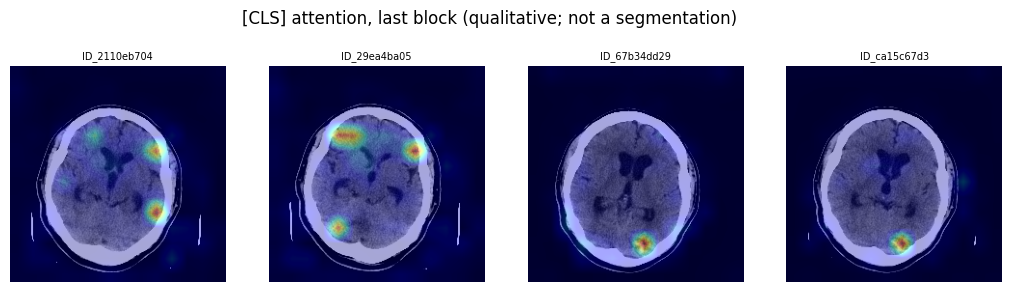

In [9]:
from src.training.experiment import load_model_from_result
from src.data.dataset import RSNASliceDataset
from src.data.preprocessing import PreprocessConfig
res = ctx.results(("B_cnn_transformer_hybrid",))
if len(res) and res.iloc[0]["status"] == "succeeded" and res.iloc[0]["config"]["model"].get("fusion", "concat") != "gap_only":
    r0 = res.iloc[0].to_dict()
    model = load_model_from_result(r0, man_info["manifest_hash"])
    test = manifest[(manifest["split"] == "test") & (manifest["any"] >= 0.5)].head(4)
    ds = RSNASliceDataset(test, ctx.rsna.train_dir, PreprocessConfig.from_dict(r0["config"]["preprocess"]))
    fig, axes = plt.subplots(1, max(len(ds), 1), figsize=(3.2 * max(len(ds), 1), 3.4))
    for i in range(len(ds)):
        x = ds[i]["image"][None].to(next(model.parameters()).device)
        with torch.no_grad():
            _, att = model.forward_features(x, return_attention=True)
        a = torch.nn.functional.interpolate(att[None], size=x.shape[-2:], mode="bilinear")[0, 0].cpu().numpy()
        img = ds[i]["image"][0].numpy(); img = (img - img.min()) / (np.ptp(img) + 1e-6)
        ax = np.atleast_1d(axes)[i]; ax.imshow(img, cmap="gray"); ax.imshow(a / (a.max() + 1e-8), cmap="jet", alpha=0.35); ax.axis("off")
        ax.set_title(test.iloc[i]["image_id"], fontsize=7)
    plt.suptitle("[CLS] attention, last block (qualitative; not a segmentation)"); plt.show()